# Sensor-Dropout Training for Robust Fault Detection under Missing Sensors

**Author:** Gabriel Rozo

**Description:** This benchmark shows that a fault detector trained with random sensor masking ("sensor dropout") keeps a much higher event-level F1 than a standard detector when sensors go missing. It builds on the overview `dataset/demos/GabrielRozo/main.ipynb`, which showed that sensor availability in the 3W Dataset is incomplete and changes from one event class to another.

## 1. Motivation

In real wells, sensors fail, freeze or are simply not installed. The overview `dataset/demos/GabrielRozo/main.ipynb` measured this in the 3W Dataset: several sensors are almost never recorded, and the set of available sensors changes with the event class.

A detector trained with every sensor present may lean on a few of them and break when they go missing. This benchmark asks a simple question: **does training with random sensor masking make the detector robust to missing sensors?**

We compare two Random Forest detectors on real events (normal vs. any fault):

- **Baseline:** trained on the features as they are.
- **Sensor dropout:** trained on the same features, but each sensor's features are replaced by their training mean with probability `P_DROP`.

Both are then tested with an increasing number of sensors removed.

## 2. Setup

In [1]:
import configparser
import importlib.metadata as md

import numpy as np
from sklearn.ensemble import RandomForestClassifier
from ThreeWToolkit.dataset import ParquetDatasetConfig, TransformConfig
from ThreeWToolkit.feature_extraction import (
    SequentialFeatureAdapterConfig,
    StatisticalConfig,
    WindowingConfig,
)
from ThreeWToolkit.preprocessing import (
    CleanSignalsConfig,
    FillLabelsConfig,
    ImputeMissingConfig,
    NormalizeConfig,
    RemapClassConfig,
    SequentialPreprocessingAdapterConfig,
)

# Experiment parameters (change these to explore other settings)
DATASET_PATH = "../../dataset"
RANDOM_SEED = 2026
WINDOW_SIZE = 128
SEEDS = [1, 2, 3]  # models trained per method, for error bars
DRAWS = 3  # random sensor subsets per number of removed sensors
P_DROP = 0.25  # chance of masking each sensor during training
THRESHOLD = 0.20  # window-level alarm threshold
K_WINDOWS = 3  # alarming windows needed to flag an event
N_TREES = 150  # trees in each Random Forest

# Versions used (feedback from the PR #217 review)
print("ThreeWToolkit:", md.version("ThreeWToolkit"))
ini = configparser.ConfigParser()
ini.read(f"{DATASET_PATH}/dataset.ini")
print("3W Dataset:", ini["VERSION"]["DATASET"])

ThreeWToolkit: 3.2.1
3W Dataset: 2.0.0


## 3. Data

We use every **real** event of the 3W Dataset and frame the task as binary: normal (class 0) versus any fault (classes 1 to 9). Events are split into train and test sets **at the event level**, so windows from the same event never appear in both sets.

In [2]:
# Real events from every class: normal (0) vs. any fault (1-9)
ds_all = ParquetDatasetConfig(
    path=DATASET_PATH, event_type=["real"], target_class=list(range(10))
).build()

# Split at the event level so windows of one event stay together
rng = np.random.default_rng(RANDOM_SEED)
files = list(ds_all.files_events)
order = rng.permutation(len(files))
n_train = int(0.85 * len(files))
train_files = [files[i] for i in order[:n_train]]
test_files = [files[i] for i in order[n_train:]]

ds_train = ParquetDatasetConfig(
    path=DATASET_PATH, split="list", file_list=train_files
).build()
ds_test = ParquetDatasetConfig(
    path=DATASET_PATH, split="list", file_list=test_files
).build()
print(f"Train: {len(ds_train)} events | Test: {len(ds_test)} events")

2026-10-30 19:22:20,461 | INFO | ThreeWToolkit.dataset.parquet_dataset | Dataset found at ..\..\dataset
2026-10-30 19:22:20,462 | INFO | ThreeWToolkit.dataset.parquet_dataset | Validating dataset integrity...
2026-10-30 19:22:20,463 | INFO | ThreeWToolkit.dataset.parquet_dataset | Dataset integrity check passed!
2026-10-30 19:22:20,539 | INFO | ThreeWToolkit.dataset.parquet_dataset | Dataset found at ..\..\dataset
2026-10-30 19:22:20,540 | INFO | ThreeWToolkit.dataset.parquet_dataset | Validating dataset integrity...
2026-10-30 19:22:20,541 | INFO | ThreeWToolkit.dataset.parquet_dataset | Dataset integrity check passed!
2026-10-30 19:22:20,626 | INFO | ThreeWToolkit.dataset.parquet_dataset | Dataset found at ..\..\dataset
2026-10-30 19:22:20,627 | INFO | ThreeWToolkit.dataset.parquet_dataset | Validating dataset integrity...
2026-10-30 19:22:20,628 | INFO | ThreeWToolkit.dataset.parquet_dataset | Dataset integrity check passed!


Train: 951 events | Test: 168 events


## 4. Features

Each event is cleaned, imputed and normalized, then cut into windows of `WINDOW_SIZE` samples. For every window we compute statistical features per sensor (mean, standard deviation, quantiles, etc.).

**Label leakage.** The raw signal includes a `state` column, which is the annotation itself. Features computed from it would reveal the answer to the model, so they are removed.

In [3]:
processor = TransformConfig(
    pre_processing=SequentialPreprocessingAdapterConfig(
        steps=[
            CleanSignalsConfig(),
            ImputeMissingConfig(),
            NormalizeConfig(),
            FillLabelsConfig(),
            RemapClassConfig(),
        ]
    ),
    feature_extraction=SequentialFeatureAdapterConfig(
        steps=[WindowingConfig(window_size=WINDOW_SIZE), StatisticalConfig()]
    ),
).build()
processor.fit(ds_train)
ds_train_t = processor.transform(ds_train)
ds_test_t = processor.transform(ds_test)

# Feature names follow "<statistic>_<sensor>". The "state" column is
# the annotation itself, so its features would leak the label.
all_cols = list(ds_train_t[0].signal.columns)
feature_cols = [c for c in all_cols if not c.endswith("_state")]
sensor_to_idx = {}
for j, col in enumerate(feature_cols):
    sensor = col.split("_", 1)[1]
    sensor_to_idx.setdefault(sensor, []).append(j)
sensors = list(sensor_to_idx)

print(f"Removed {len(all_cols) - len(feature_cols)} leaking features")
print(f"Kept {len(feature_cols)} features from {len(sensors)} sensors:")
print(", ".join(sensors))

Removed 10 leaking features
Kept 150 features from 15 sensors:
ESTADO-DHSV, ESTADO-M1, ESTADO-M2, ESTADO-PXO, ESTADO-SDV-GL, ESTADO-SDV-P, ESTADO-W1, ESTADO-W2, ESTADO-XO, P-ANULAR, P-JUS-CKGL, P-MON-CKP, P-TPT, T-JUS-CKP, T-TPT


In [4]:
def to_matrix(event):
    """Return the leak-free feature matrix of one transformed event."""
    x = event.signal[feature_cols].to_numpy(dtype=float)
    return np.nan_to_num(x, nan=0.0, posinf=0.0, neginf=0.0)


def window_labels(event):
    """Return 1 for windows labeled with any fault, 0 for normal."""
    return (np.asarray(event.label) != 0).astype(int)


# Training data: all windows stacked into one matrix
X_parts, y_parts = [], []
for i in range(len(ds_train_t)):
    event = ds_train_t[i]
    X_parts.append(to_matrix(event))
    y_parts.append(window_labels(event))
X_train = np.vstack(X_parts)
y_train = np.concatenate(y_parts)
del X_parts, y_parts  # free the per-event copies

# Test data: kept per event, because we score whole events
test_events = []
for i in range(len(ds_test_t)):
    event = ds_test_t[i]
    test_events.append((to_matrix(event), bool(window_labels(event).any())))

n_fault = sum(fault for _, fault in test_events)
print(f"Train: {X_train.shape[0]} windows, {y_train.mean():.0%} labeled fault")
print(f"Test: {len(test_events)} events, {n_fault} with a fault")

Train: 217204 windows, 47% labeled fault
Test: 168 events, 76 with a fault


## 5. Scoring and simulated sensor loss

A model scores each window, and an event is flagged as faulty when at least `K_WINDOWS` windows reach the `THRESHOLD` probability. We report event-level recall, precision and F1.

To simulate missing sensors at test time, the features of the removed sensors are replaced by their training means, as a typical imputation would do. For each number of removed sensors, scores are averaged over `DRAWS` random choices of which sensors are removed.

In [5]:
feat_means = X_train.mean(axis=0)


def mask_sensors(events, removed):
    """Replace the features of the removed sensors by training means."""
    cols = [j for s in removed for j in sensor_to_idx[s]]
    masked = []
    for x, fault in events:
        x = x.copy()
        x[:, cols] = feat_means[cols]
        masked.append((x, fault))
    return masked


def event_scores(model, events):
    """Event-level recall, precision and F1 of a window-level model."""
    tp = fp = fn = 0
    for x, fault in events:
        alarms = (model.predict_proba(x)[:, 1] >= THRESHOLD).sum()
        flagged = alarms >= K_WINDOWS
        tp += fault and flagged
        fp += (not fault) and flagged
        fn += fault and not flagged
    recall = tp / (tp + fn) if tp + fn else 0.0
    precision = tp / (tp + fp) if tp + fp else 0.0
    f1 = 2 * precision * recall / (precision + recall) if tp else 0.0
    return recall, precision, f1


def degradation_curve(model, seed):
    """Mean event scores for 0..N removed sensors, over random draws."""
    rng = np.random.default_rng(seed)
    curve = []
    for k in range(len(sensors) + 1):
        draws = [
            event_scores(
                model,
                mask_sensors(test_events, rng.choice(sensors, k, replace=False)),
            )
            for _ in range(DRAWS)
        ]
        curve.append(np.mean(draws, axis=0))
    return np.array(curve)  # rows: removed sensors; cols: R, P, F1

## 6. Methods

Both methods use the same Random Forest settings. The only difference is the training data: the sensor-dropout model sees each sensor masked (replaced by its training mean) with probability `P_DROP`, independently for every window and sensor. This forces it to rely on several sensors instead of a few.

In [6]:
def train_baseline(seed):
    """Random Forest trained on the features as they are."""
    model = RandomForestClassifier(
        n_estimators=N_TREES, class_weight="balanced", random_state=seed, n_jobs=-1
    )
    return model.fit(X_train, y_train)


def train_sensor_dropout(seed):
    """Random Forest trained with random sensor masking (P_DROP)."""
    rng = np.random.default_rng(seed)
    x = X_train.copy()
    dropped = rng.random((len(x), len(sensors))) < P_DROP
    for s_i, sensor in enumerate(sensors):
        cols = sensor_to_idx[sensor]
        x[np.ix_(dropped[:, s_i], cols)] = feat_means[cols]
    model = RandomForestClassifier(
        n_estimators=N_TREES, class_weight="balanced", random_state=seed, n_jobs=-1
    )
    return model.fit(x, y_train)

## 7. Results

Each method is trained once per seed in `SEEDS`, and each trained model is scored with 0 to 15 sensors removed.

In [7]:
results = {"Baseline": [], "Sensor dropout": []}
for seed in SEEDS:
    results["Baseline"].append(degradation_curve(train_baseline(seed), seed))
    results["Sensor dropout"].append(
        degradation_curve(train_sensor_dropout(seed), seed)
    )
    print(f"Seed {seed} done")
results = {name: np.array(curves) for name, curves in results.items()}
# Save the scores so the figure can be rebuilt without the long run
np.savez(
    "results.npz",
    baseline=results["Baseline"],
    sensor_dropout=results["Sensor dropout"],
)

Seed 1 done
Seed 2 done
Seed 3 done


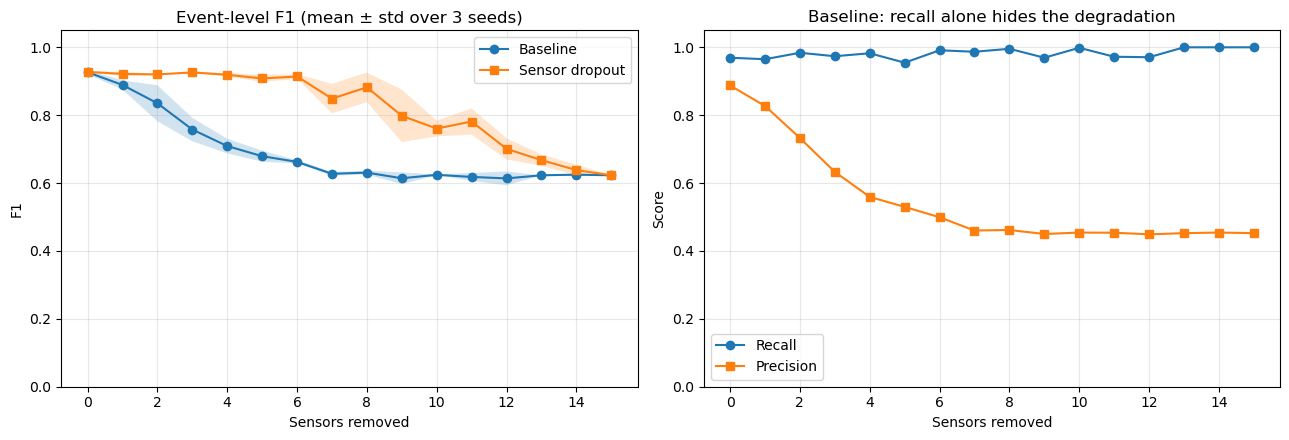

Event-level F1, mean ± std over seeds
 removed |      Baseline | Sensor dropout
       0 | 0.927 ± 0.006 |  0.928 ± 0.002
       2 | 0.835 ± 0.053 |  0.920 ± 0.002
       4 | 0.709 ± 0.022 |  0.919 ± 0.005
       6 | 0.662 ± 0.005 |  0.914 ± 0.007
       8 | 0.631 ± 0.006 |  0.882 ± 0.044
      10 | 0.624 ± 0.001 |  0.761 ± 0.023
      12 | 0.614 ± 0.020 |  0.701 ± 0.031
      15 | 0.623 ± 0.000 |  0.623 ± 0.000


In [8]:
# This cell only needs results.npz, so the figure can be rebuilt
# without running the long experiment above.
import matplotlib.pyplot as plt
import numpy as np

saved = np.load("results.npz")
results = {
    "Baseline": saved["baseline"],
    "Sensor dropout": saved["sensor_dropout"],
}
n_seeds = results["Baseline"].shape[0]
k = np.arange(results["Baseline"].shape[1])

fig, (ax_f1, ax_why) = plt.subplots(1, 2, figsize=(13, 4.5))
for name, marker in [("Baseline", "o"), ("Sensor dropout", "s")]:
    f1 = results[name][:, :, 2]
    mean, std = f1.mean(axis=0), f1.std(axis=0)
    ax_f1.plot(k, mean, marker=marker, label=name)
    ax_f1.fill_between(k, mean - std, mean + std, alpha=0.2)
ax_f1.set(
    title=f"Event-level F1 (mean ± std over {n_seeds} seeds)",
    xlabel="Sensors removed",
    ylabel="F1",
    ylim=(0, 1.05),
)
ax_f1.legend()

base = results["Baseline"].mean(axis=0)
ax_why.plot(k, base[:, 0], marker="o", label="Recall")
ax_why.plot(k, base[:, 1], marker="s", label="Precision")
ax_why.set(
    title="Baseline: recall alone hides the degradation",
    xlabel="Sensors removed",
    ylabel="Score",
    ylim=(0, 1.05),
)
ax_why.legend()

for ax in (ax_f1, ax_why):
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("robustness_f1.png", dpi=150, bbox_inches="tight")
plt.show()

print("Event-level F1, mean ± std over seeds")
print(f"{'removed':>8} | {'Baseline':>13} | {'Sensor dropout':>14}")
for n in (0, 2, 4, 6, 8, 10, 12, 15):
    cells = []
    for name in results:
        f1 = results[name][:, n, 2]
        cells.append(f"{f1.mean():.3f} ± {f1.std():.3f}")
    print(f"{n:>8} | {cells[0]:>13} | {cells[1]:>14}")

## 8. Discussion

- **No cost on complete data.** With all sensors available, both detectors reach the same event-level F1 (about 0.93).
- **Much slower degradation.** As sensors go missing, the baseline degrades quickly: its F1 drops to 0.71 with 4 sensors removed and to 0.66 with 6. The sensor-dropout detector stays above 0.91 up to 6 removed sensors, with a small spread across seeds.
- **Why F1 and not recall.** The right panel shows that the baseline keeps a recall close to 1 even when sensors are missing, because without information it raises alarms on almost every event. Its precision falls from 0.89 to about 0.45. An evaluation based on recall alone would hide this degradation.
- **The common floor.** With all 15 sensors removed, both models reach the same F1 (about 0.62), which corresponds to flagging every event. No method can detect faults without data, so this is the expected limit.

## 9. Limitations and next steps

- **Simulated sensor loss.** Missing sensors are simulated by replacing their features with training means. Real failures can look different (frozen values, spikes, slow drift), so testing on events where sensors are genuinely missing is the natural next step.
- **Sensor selection.** The 15 sensors are the ones kept by `CleanSignals` on the training set. The overview `dataset/demos/GabrielRozo/main.ipynb` observed that this step can select different columns across runs, so other runs may use a slightly different sensor set.
- **One model family.** Only Random Forests on statistical features were tested. The same idea applies to neural networks, where masking groups of inputs during training is straightforward.
- **Untuned settings.** `P_DROP`, `THRESHOLD` and `K_WINDOWS` were fixed by hand. A sweep over `P_DROP` would show how much masking is needed.
- **Class imbalance among faults.** Most real fault events belong to class 4, so the fault side of the task is dominated by that class.